# Pergunta de Pesquisa 4 (PP4)

In [1]:
import sys
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Garante acesso ao módulo src a partir de metrics/
if str(Path("..").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("..").resolve()))

# Configurações visuais padronizadas para publicação acadêmica / TCC
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Paleta acadêmica consistente
PALETTE_STRAT = {
    'Zero-Shot': '#2b5c8f',   # Azul escuro sóbrio
    'Few-Shot': '#2a9d8f',    # Verde azulado / Teal
    'CoT Pólya': '#e76f51'    # Terracota / Laranja escuro
}

PALETTE_VERDICTS = {
    'AC': '#2ca02c',   # Verde
    'WA': '#d62728',   # Vermelho
    'RE': '#9467bd',   # Roxo
    'TLE': '#ff7f0e',  # Laranja
    'MLE': '#8c564b',  # Marrom
    'CE': '#7f7f7f'    # Cinza
}

print("Ambiente configurado com sucesso para análise da RQ4 (Temperatura T=0, Linguagem C).")


Ambiente configurado com sucesso para análise da RQ4 (Temperatura T=0, Linguagem C).


In [2]:
# 1. Carregamento do dataset e análise das propriedades dos problemas
path_database = Path("../database/dataset_obi_senior/")
questions_path = sorted([p for p in path_database.glob("*") if p.is_dir()])

problem_info = []
for q_dir in questions_path:
    prob_json = q_dir / "problem.json"
    if prob_json.exists():
        with open(prob_json, "r", encoding="utf-8") as f:
            data = json.load(f)
        problem_info.append({
            "name": q_dir.name,
            "year": data.get("year", "-"),
            "level": data.get("level", "-"),
            "period": data.get("period", "-"),
            "time_limit": data.get("time_limit", 1.0),
            "memory_limit": data.get("memory_limit", 256),
            "topics": data.get("topics", [])
        })

df_problems = pd.DataFrame(problem_info)
TOTAL_PROBLEMS = len(df_problems)

print(f"Total de problemas no dataset: {TOTAL_PROBLEMS}")
print("\nDistribuição de fases (períodos) da OBI:")
print(df_problems['period'].value_counts().to_string())
print("\nResumo de limites de execução:")
display(df_problems[['time_limit', 'memory_limit']].describe().round(2))


Total de problemas no dataset: 125

Distribuição de fases (períodos) da OBI:
period
Fase 2              32
Fase 1              27
Fase 3              25
Fase Local          16
Fase Nacional       15
Fase Estadual        6
Fase 2 - Turno B     4

Resumo de limites de execução:


,time_limit,memory_limit
count,125.00,125.00
mean,3.58,456.70
std,2.31,261.28
min,1.00,256.00
25%,2.00,256.00
50%,4.00,256.00
75%,5.00,512.00
max,15.00,1024.00


## 1. Desempenho do Baseline em C (Zero-Shot, T=0)

In [3]:
# Carregamento dos dados do Baseline (Zero-Shot) em C da RQ1 (T=0)
main_models = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GPT-6 Luna"]
model_slugs = {
    "DeepSeek v4.1 Flash": "deepseek_deepseek-v4.1-flash",
    "Gemini 3.8 Flash": "gemini-3.8-flash",
    "GPT-6 Luna": "openai_gpt-6-luna"
}
verdict_order = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

base_results = Path("../results/dataset_obi_senior")

def load_prompt_results(model_slug: str, prompt_slug: str, lang: str = "c") -> pd.DataFrame:
    json_dir = base_results / model_slug / prompt_slug / lang / "text"
    rows = []
    for q_dir in questions_path:
        q_name = q_dir.name
        jf = json_dir / f"{q_name}.json"
        if jf.exists():
            try:
                with open(jf, "r", encoding="utf-8") as f:
                    data = json.load(f)
                entry = data[-1] if isinstance(data, list) else data
                jr = entry.get("judge_result", {})
                counts = jr.get("counts", {})
                tok = entry.get("tokens", {})
                cst = entry.get("cost_usd", {})
                
                rows.append({
                    "question_name": q_name,
                    "judge_predict": jr.get("judge_predict", "CE"),
                    "execution_time": float(jr.get("execution_time", 0.0)),
                    "AC": counts.get("AC", 0),
                    "WA": counts.get("WA", 0),
                    "RE": counts.get("RE", 0),
                    "TLE": counts.get("TLE", 0),
                    "MLE": counts.get("MLE", 0),
                    "CE": counts.get("CE", 0),
                    "total_test_cases": jr.get("total_test_cases", 0),
                    "input_tokens": tok.get("input_tokens", 0),
                    "output_tokens": tok.get("output_tokens", 0),
                    "total_tokens": tok.get("total_tokens", 0),
                    "cost_usd": cst.get("total_cost", 0.0),
                    "raw_response": entry.get("raw_response", ""),
                    "extracted_code": entry.get("extracted_code", "")
                })
            except Exception as e:
                pass
                
    if len(rows) > 0:
        return pd.DataFrame(rows)
    return pd.DataFrame(columns=["question_name", "judge_predict", "execution_time", "AC", "WA", "RE", "TLE", "MLE", "CE"])

datas_zero_shot = {m: load_prompt_results(slug, "zero_shot", lang="c") for m, slug in model_slugs.items()}

# Consolidação tabular do Baseline em C
baseline_summary = []
for m in main_models:
    df_m = datas_zero_shot[m]
    vc = df_m['judge_predict'].value_counts().to_dict()
    ac = vc.get('AC', 0)
    wa = vc.get('WA', 0)
    re_ = vc.get('RE', 0)
    tle = vc.get('TLE', 0)
    mle = vc.get('MLE', 0)
    ce = vc.get('CE', 0)
    acc = (ac / TOTAL_PROBLEMS) * 100
    t_mean = df_m['execution_time'].mean()
    
    baseline_summary.append({
        "Modelo": m,
        "Estratégia": "Zero-Shot (Base)",
        "AC": ac,
        "Pass@1 (%)": f"{acc:.2f}%",
        "WA": wa,
        "RE": re_,
        "TLE": tle,
        "MLE": mle,
        "CE": ce,
        "Tempo Médio (s)": f"{t_mean:.3f}s"
    })

df_baseline = pd.DataFrame(baseline_summary)
print("=== DESEMPENHO EM C NO BASELINE (ZERO-SHOT, T=0 - RQ1) ===")
display(df_baseline)


=== DESEMPENHO EM C NO BASELINE (ZERO-SHOT, T=0 - RQ1) ===


,Modelo,Estratégia,AC,Pass@1 (%),WA,RE,TLE,MLE,CE,Tempo Médio (s)
0,DeepSeek v4.1 Flash,Zero-Shot (Base),118,94.40%,3,1,0,0,3,0.196s
1,Gemini 3.8 Flash,Zero-Shot (Base),116,92.80%,6,0,0,0,3,0.149s
2,GPT-6 Luna,Zero-Shot (Base),105,84.00%,15,0,0,0,5,0.238s


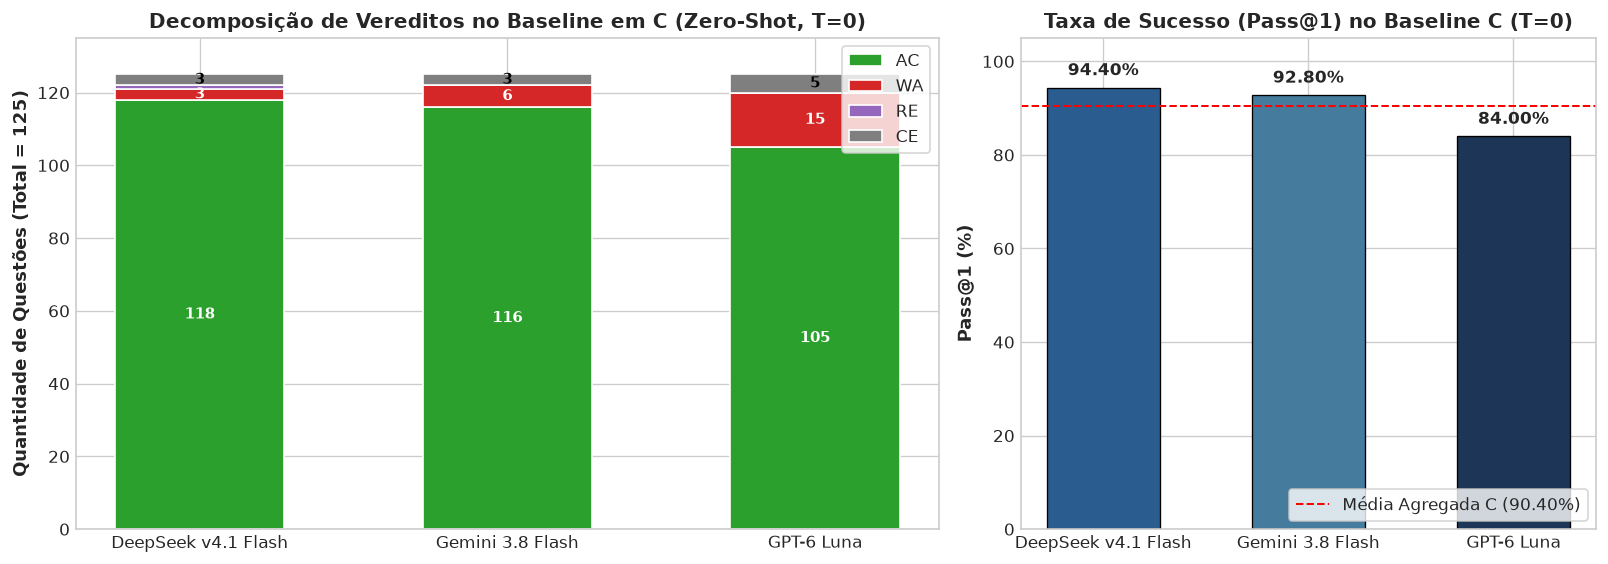

In [4]:
# Gráfico 1: Vereditos e Taxas de Acerto no Baseline Zero-Shot em C (T=0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})

x = np.arange(len(main_models))
bottom = np.zeros(len(main_models))

for v in verdict_order:
    vals = [datas_zero_shot[m]['judge_predict'].value_counts().get(v, 0) for m in main_models]
    if sum(vals) > 0:
        bars = ax1.bar(x, vals, bottom=bottom, label=v, color=PALETTE_VERDICTS[v], edgecolor='white', width=0.55)
        for i, val in enumerate(vals):
            if val >= 3:
                ax1.text(x[i], bottom[i] + val / 2, str(val), ha='center', va='center',
                         color='white' if v in ['AC', 'WA', 'RE'] else 'black', fontweight='bold', fontsize=9)
        bottom += np.array(vals)

ax1.set_title("Decomposição de Vereditos no Baseline em C (Zero-Shot, T=0)")
ax1.set_xticks(x)
ax1.set_xticklabels(main_models)
ax1.set_ylabel("Quantidade de Questões (Total = 125)")
ax1.set_ylim(0, 135)
ax1.legend(loc='upper right', frameon=True)

accs = [(datas_zero_shot[m]['judge_predict'] == 'AC').mean() * 100 for m in main_models]
bars2 = ax2.bar(x, accs, color=['#2b5c8f', '#457b9d', '#1d3557'], width=0.55, edgecolor='black', linewidth=0.8)
ax2.set_title("Taxa de Sucesso (Pass@1) no Baseline C (T=0)")
ax2.set_xticks(x)
ax2.set_xticklabels(main_models)
ax2.set_ylabel("Pass@1 (%)")
ax2.set_ylim(0, 105)
ax2.axhline(90.40, color='red', linestyle='--', linewidth=1.2, label='Média Agregada C (90.40%)')

for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.8, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')

ax2.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 2. Comparativo das Estratégias de Prompting em C (T=0)

In [5]:
# Carregamento de Few-Shot e CoT Pólya em C (T=0)
datas_few_shot = {m: load_prompt_results(slug, "few_shot_java", lang="c") for m, slug in model_slugs.items()}
datas_cot_polya = {m: load_prompt_results(slug, "chain_of_thought_polya", lang="c") for m, slug in model_slugs.items()}

print("Status do carregamento do pipeline experimental da RQ4 (T=0, Linguagem C):")
for m in main_models:
    print(f"* {m:20s}: Zero-Shot = {len(datas_zero_shot[m]):3d} | Few-Shot = {len(datas_few_shot[m]):3d} | CoT Pólya = {len(datas_cot_polya[m]):3d} questões.")


Status do carregamento do pipeline experimental da RQ4 (T=0, Linguagem C):
* DeepSeek v4.1 Flash : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões.
* Gemini 3.8 Flash    : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões.
* GPT-6 Luna          : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões.


In [6]:
# Consolidação do Quadro Comparativo da RQ4: Zero-Shot vs. Few-Shot vs. CoT Pólya (T=0, C)
comparative_rows = []

strategies = [
    ("Zero-Shot", datas_zero_shot),
    ("Few-Shot", datas_few_shot),
    ("CoT Pólya", datas_cot_polya)
]

for strat_name, strat_dict in strategies:
    tot_ac = 0
    tot_wa, tot_re, tot_tle, tot_mle, tot_ce = 0, 0, 0, 0, 0
    tot_time = 0.0
    
    for m in main_models:
        df_sub = strat_dict[m]
        vc = df_sub["judge_predict"].value_counts().to_dict()
        ac = vc.get("AC", 0)
        wa = vc.get("WA", 0)
        re_ = vc.get("RE", 0)
        tle = vc.get("TLE", 0)
        mle = vc.get("MLE", 0)
        ce = vc.get("CE", 0)
        t_mean = df_sub["execution_time"].mean()
        
        b_ac = (datas_zero_shot[m]["judge_predict"] == "AC").sum()
        delta_ac = ac - b_ac
        
        tot_ac += ac
        tot_wa += wa
        tot_re += re_
        tot_tle += tle
        tot_mle += mle
        tot_ce += ce
        tot_time += t_mean
        
        comparative_rows.append({
            "Modelo": m,
            "Estratégia": strat_name,
            "AC (de 125)": ac,
            "Pass@1 (%)": f"{(ac / TOTAL_PROBLEMS) * 100:.2f}%",
            "Delta AC": f"{delta_ac:+d}" if strat_name != "Zero-Shot" else "Ref.",
            "WA": wa,
            "RE": re_,
            "TLE": tle,
            "MLE": mle,
            "CE": ce,
            "Tempo Médio": f"{t_mean:.3f}s"
        })
        
    # Linha Agregada da Estratégia
    b_tot_ac = sum((datas_zero_shot[m]["judge_predict"] == "AC").sum() for m in main_models)
    d_tot = tot_ac - b_tot_ac
    comparative_rows.append({
        "Modelo": "AGREGADO (375)",
        "Estratégia": strat_name,
        "AC (de 125)": f"{tot_ac} / 375",
        "Pass@1 (%)": f"{(tot_ac / (TOTAL_PROBLEMS * 3)) * 100:.2f}%",
        "Delta AC": f"{d_tot:+d}" if strat_name != "Zero-Shot" else "Ref.",
        "WA": tot_wa,
        "RE": tot_re,
        "TLE": tot_tle,
        "MLE": tot_mle,
        "CE": tot_ce,
        "Tempo Médio": f"{tot_time / 3:.3f}s"
    })

df_rq4_comp = pd.DataFrame(comparative_rows)
print("=== QUADRO COMPARATIVO RQ4: ZERO-SHOT vs. FEW-SHOT vs. COT PÓLYA (T=0, C) ===")
display(df_rq4_comp)


=== QUADRO COMPARATIVO RQ4: ZERO-SHOT vs. FEW-SHOT vs. COT PÓLYA (T=0, C) ===


,Modelo,Estratégia,AC (de 125),Pass@1 (%),Delta AC,WA,RE,TLE,MLE,CE,Tempo Médio
0,DeepSeek v4.1 Flash,Zero-Shot,118,94.40%,Ref.,3,1,0,0,3,0.196s
1,Gemini 3.8 Flash,Zero-Shot,116,92.80%,Ref.,6,0,0,0,3,0.149s
2,GPT-6 Luna,Zero-Shot,105,84.00%,Ref.,15,0,0,0,5,0.238s
3,AGREGADO (375),Zero-Shot,339 / 375,90.40%,Ref.,24,1,0,0,11,0.194s
4,DeepSeek v4.1 Flash,Few-Shot,116,92.80%,-2,5,0,0,0,4,0.242s
5,Gemini 3.8 Flash,Few-Shot,119,95.20%,+3,6,0,0,0,0,0.165s
6,GPT-6 Luna,Few-Shot,113,90.40%,+8,10,1,1,0,0,0.247s
7,AGREGADO (375),Few-Shot,348 / 375,92.80%,+9,21,1,1,0,4,0.218s
8,DeepSeek v4.1 Flash,CoT Pólya,109,87.20%,-9,3,0,0,0,13,0.150s
9,Gemini 3.8 Flash,CoT Pólya,121,96.80%,+5,4,0,0,0,0,0.162s


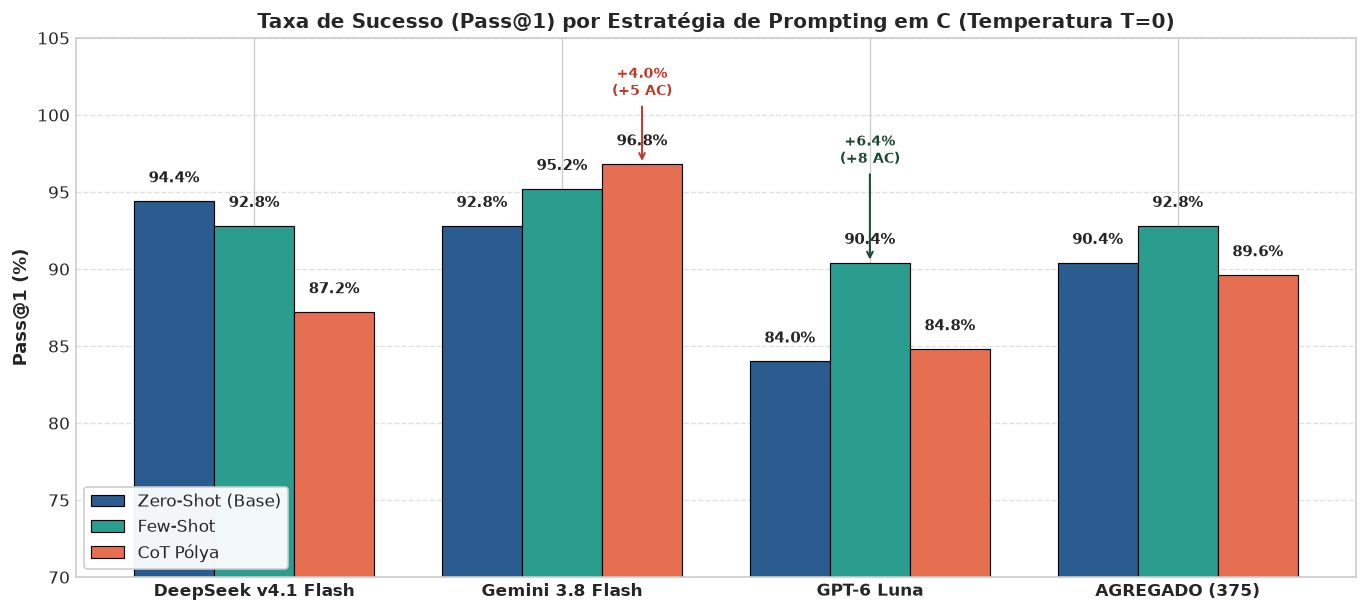

In [7]:
# Gráfico 2: Comparativo Direto de Taxa de Acerto (Pass@1) por Estratégia em C (T=0)
fig, ax = plt.subplots(figsize=(11.5, 5.2))

x_pos = np.arange(len(main_models) + 1)
bar_width = 0.26

zero_vals = [(datas_zero_shot[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]
few_vals = [(datas_few_shot[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]
cot_vals = [(datas_cot_polya[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]

zero_vals.append(sum((datas_zero_shot[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)
few_vals.append(sum((datas_few_shot[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)
cot_vals.append(sum((datas_cot_polya[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)

labels_x = main_models + ["AGREGADO (375)"]

b1 = ax.bar(x_pos - bar_width, zero_vals, width=bar_width, label="Zero-Shot (Base)",
            color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', linewidth=0.7)
b2 = ax.bar(x_pos, few_vals, width=bar_width, label="Few-Shot",
            color=PALETTE_STRAT['Few-Shot'], edgecolor='black', linewidth=0.7)
b3 = ax.bar(x_pos + bar_width, cot_vals, width=bar_width, label="CoT Pólya",
            color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', linewidth=0.7)

ax.set_title("Taxa de Sucesso (Pass@1) por Estratégia de Prompting em C (Temperatura T=0)")
ax.set_ylabel("Pass@1 (%)")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_x, fontweight='bold')
ax.set_ylim(70, 105)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(loc='lower left', frameon=True, framealpha=0.95)

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# Destaques analíticos pontuais
ax.annotate('+6.4%\n(+8 AC)', xy=(x_pos[2], few_vals[2]), xytext=(x_pos[2], few_vals[2] + 6.5),
            ha='center', fontsize=8.5, fontweight='bold', color='#1b4931',
            arrowprops=dict(arrowstyle='->', color='#1b4931', lw=1.2))

ax.annotate('+4.0%\n(+5 AC)', xy=(x_pos[1] + bar_width, cot_vals[1]), xytext=(x_pos[1] + bar_width, cot_vals[1] + 4.5),
            ha='center', fontsize=8.5, fontweight='bold', color='#c0392b',
            arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.2))

plt.tight_layout()
plt.show()


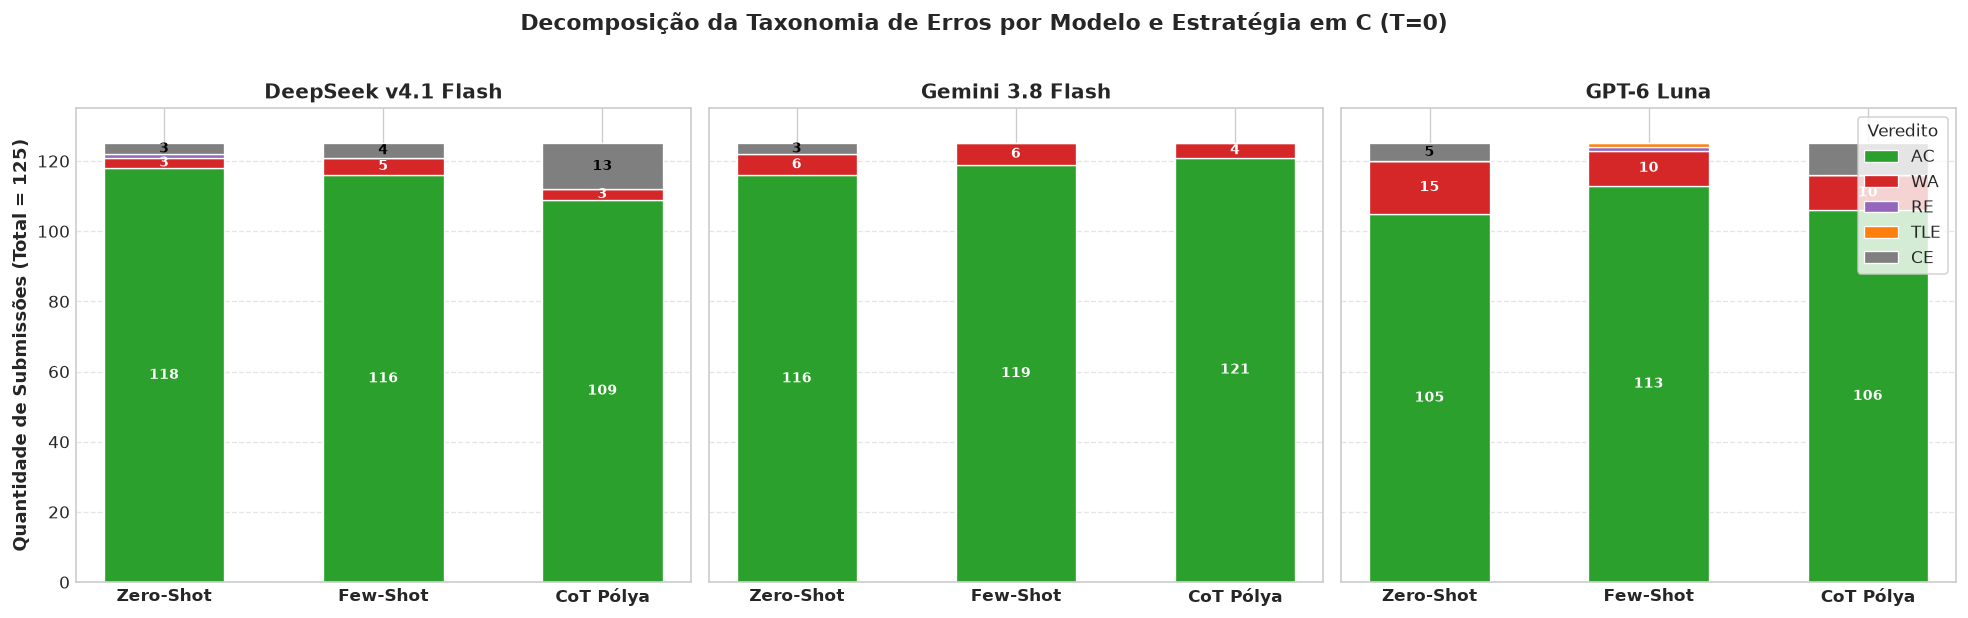

In [8]:
# Gráfico 3: Decomposição da Taxonomia de Erros por Modelo e Estratégia em C (T=0)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.0), sharey=True)

strats = ["Zero-Shot", "Few-Shot", "CoT Pólya"]
x_m = np.arange(len(strats))
bar_w = 0.55

for idx, m in enumerate(main_models):
    ax = axes[idx]
    bottom = np.zeros(len(strats))
    dfs_m = [datas_zero_shot[m], datas_few_shot[m], datas_cot_polya[m]]
    
    for v in verdict_order:
        vals = [df_s['judge_predict'].value_counts().get(v, 0) for df_s in dfs_m]
        if sum(vals) > 0:
            bars = ax.bar(x_m, vals, bottom=bottom, label=v, color=PALETTE_VERDICTS[v],
                          edgecolor='white', linewidth=0.8, width=bar_w)
            for j, val in enumerate(vals):
                if val >= 3:
                    ax.text(x_m[j], bottom[j] + val / 2, str(val), ha='center', va='center',
                            color='white' if v in ['AC', 'WA', 'RE'] else 'black', fontweight='bold', fontsize=8.5)
            bottom += np.array(vals)
            
    ax.set_title(f"{m}")
    ax.set_xticks(x_m)
    ax.set_xticklabels(strats, fontweight='bold')
    if idx == 0:
        ax.set_ylabel("Quantidade de Submissões (Total = 125)")
    ax.set_ylim(0, 135)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

axes[2].legend(loc='upper right', frameon=True, title="Veredito")
plt.suptitle("Decomposição da Taxonomia de Erros por Modelo e Estratégia em C (T=0)", y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Auditoria dos Casos de Erro de Compilação (CE) no CoT Pólya

In [9]:
# Sanity Check Metodológico: Detecção de Código C Válido nos Casos de CE do CoT
import re

def inspect_ce_cases_c(model_slug: str, prompt_slug: str = "chain_of_thought_polya"):
    p_dir = base_results / model_slug / prompt_slug / "c" / "text"
    ce_records = []
    
    for f in sorted(p_dir.glob("*.json")):
        with open(f, "r", encoding="utf-8") as fp:
            data = json.load(fp)[0]
        jr = data.get("judge_result", {})
        if jr.get("judge_predict") == "CE":
            raw = data.get("raw_response", "")
            ext = data.get("extracted_code", "")
            
            match_c = re.findall(r"```c\s*\n(.*?)```", raw, re.DOTALL | re.IGNORECASE)
            has_c_block = len(match_c) > 0
            has_main = any("main" in b for b in match_c)
            code_len = len(match_c[0].strip()) if has_c_block else 0
            
            ce_records.append({
                "Questão": f.stem,
                "Texto Extraído Incorretamente": ext.strip().replace("\n", " ")[:45] + "...",
                "Contém Bloco ```c": "Sim" if has_c_block else "Não",
                "Contém Função main()": "Sim" if has_main else "Não",
                "Tamanho do Código Real (chars)": code_len
            })
    return pd.DataFrame(ce_records)

df_ce_deepseek = inspect_ce_cases_c("deepseek_deepseek-v4.1-flash")
df_ce_gpt = inspect_ce_cases_c("openai_gpt-6-luna")

print(f"=== DIAGNÓSTICO METODOLÓGICO: PARSER ARTIFACT NO COT PÓLYA EM C (T=0) ===")
print(f"* DeepSeek v4.1 Flash: Total de CEs = {len(df_ce_deepseek)} | Casos com código C completo oculto = {(df_ce_deepseek['Contém Função main()'] == 'Sim').sum()}")
print(f"* GPT-6 Luna         : Total de CEs = {len(df_ce_gpt)} | Casos com código C completo oculto = {(df_ce_gpt['Contém Função main()'] == 'Sim').sum()}")

print("\nAmostra de Casos Afetados pelo Parser no GPT-6 Luna:")
display(df_ce_gpt.head(7))


=== DIAGNÓSTICO METODOLÓGICO: PARSER ARTIFACT NO COT PÓLYA EM C (T=0) ===
* DeepSeek v4.1 Flash: Total de CEs = 13 | Casos com código C completo oculto = 6
* GPT-6 Luna         : Total de CEs = 9 | Casos com código C completo oculto = 8

Amostra de Casos Afetados pelo Parser no GPT-6 Luna:


,Questão,Texto Extraído Incorretamente,Contém Bloco ```c,Contém Função main(),Tamanho do Código Real (chars)
0,Fast-Food,Para verificar se um prédio tem algum vizinho...,Sim,Sim,5062
1,Festa Junina,A solução usa tempo **O(1)** e espaço **O(1)*...,Sim,Sim,336
2,Festa olímpica,"Isso ocorre porque, entre cada `T - 1` posiçõ...",Sim,Sim,887
3,Game-10,Somar `N` antes do módulo garante que o valor...,Sim,Sim,229
4,Jogo de Pratos,## 1. Compreensão do problema As refeições p...,Não,Não,0
5,Pirâmide,"Essa fórmula gera valores `1` na borda, `2` n...",Sim,Sim,524
6,Quadrado,"Escolhemos `escala = máximo(a) + 1`. Assim, a...",Sim,Sim,818


## 4. Tempo de Execução no Judge (T=0)

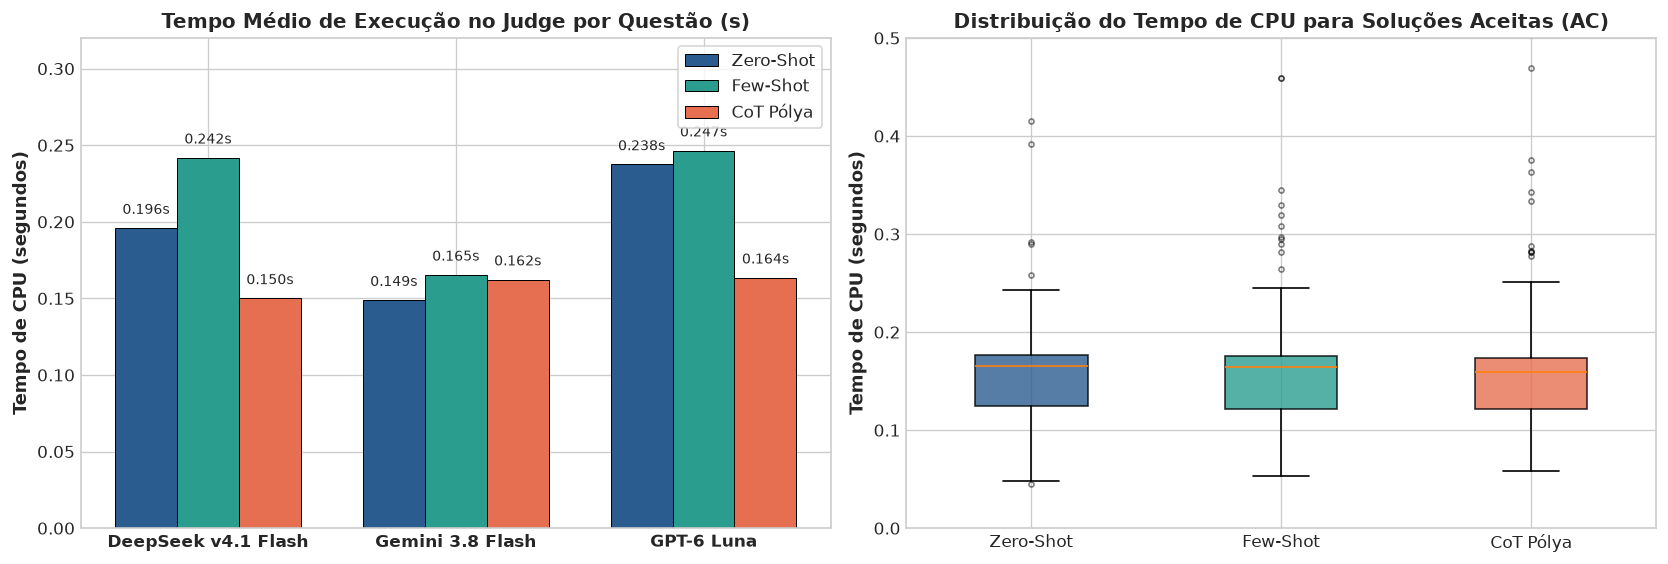

In [10]:
# Gráfico 4: Análise de Tempo de Execução no Judge por Estratégia em C (T=0)
fig, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(14, 4.8))

x_t = np.arange(len(main_models))
w_t = 0.25

t_zero = [datas_zero_shot[m]["execution_time"].mean() for m in main_models]
t_few = [datas_few_shot[m]["execution_time"].mean() for m in main_models]
t_cot = [datas_cot_polya[m]["execution_time"].mean() for m in main_models]

b4a = ax4a.bar(x_t - w_t, t_zero, width=w_t, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
b4b = ax4a.bar(x_t, t_few, width=w_t, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
b4c = ax4a.bar(x_t + w_t, t_cot, width=w_t, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)

ax4a.set_title("Tempo Médio de Execução no Judge por Questão (s)")
ax4a.set_xticks(x_t)
ax4a.set_xticklabels(main_models, fontweight='bold')
ax4a.set_ylabel("Tempo de CPU (segundos)")
ax4a.set_ylim(0, 0.32)
ax4a.legend(loc='upper right', frameon=True)

for bars in [b4a, b4b, b4c]:
    for b in bars:
        h = b.get_height()
        ax4a.text(b.get_x() + b.get_width() / 2, h + 0.007, f"{h:.3f}s", ha='center', va='bottom', fontsize=8.5)

# 4b. Boxplot nativo em matplotlib de distribuição dos tempos de execução para AC
time_zero = [t for m in main_models for t in datas_zero_shot[m][datas_zero_shot[m]["judge_predict"] == "AC"]["execution_time"]]
time_few = [t for m in main_models for t in datas_few_shot[m][datas_few_shot[m]["judge_predict"] == "AC"]["execution_time"]]
time_cot = [t for m in main_models for t in datas_cot_polya[m][datas_cot_polya[m]["judge_predict"] == "AC"]["execution_time"]]

bp = ax4b.boxplot([time_zero, time_few, time_cot], tick_labels=["Zero-Shot", "Few-Shot", "CoT Pólya"],
                  patch_artist=True, widths=0.45, showfliers=True,
                  flierprops=dict(marker='o', markersize=3, alpha=0.5))

colors_bp = [PALETTE_STRAT['Zero-Shot'], PALETTE_STRAT['Few-Shot'], PALETTE_STRAT['CoT Pólya']]
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax4b.set_title("Distribuição do Tempo de CPU para Soluções Aceitas (AC)")
ax4b.set_ylabel("Tempo de CPU (segundos)")
ax4b.set_ylim(0, 0.5)

plt.tight_layout()
plt.show()


## 5. Transições por Questão e Desempenho por Fase da OBI

In [11]:
# Mapeamento de problemas recuperados e degradados por modelo em C (T=0)
transition_rows = []

for m in main_models:
    zero_map = dict(zip(datas_zero_shot[m]["question_name"], datas_zero_shot[m]["judge_predict"]))
    few_map = dict(zip(datas_few_shot[m]["question_name"], datas_few_shot[m]["judge_predict"]))
    cot_map = dict(zip(datas_cot_polya[m]["question_name"], datas_cot_polya[m]["judge_predict"]))
    
    rec_fs = [q for q in zero_map if zero_map[q] != 'AC' and few_map.get(q) == 'AC']
    deg_fs = [q for q in zero_map if zero_map[q] == 'AC' and few_map.get(q) != 'AC']
    rec_cot = [q for q in zero_map if zero_map[q] != 'AC' and cot_map.get(q) == 'AC']
    deg_cot = [q for q in zero_map if zero_map[q] == 'AC' and cot_map.get(q) != 'AC']
    
    transition_rows.append({
        "Modelo": m,
        "Recuperados Few-Shot (Qtd)": len(rec_fs),
        "Degradados Few-Shot (Qtd)": len(deg_fs),
        "Delta Few-Shot": f"{len(rec_fs) - len(deg_fs):+d}",
        "Recuperados CoT (Qtd)": len(rec_cot),
        "Degradados CoT (Qtd)": len(deg_cot),
        "Delta CoT": f"{len(rec_cot) - len(deg_cot):+d}"
    })

print("=== BALANÇO DE PROMOÇÕES E DEGRADAÇÕES RELATIVAS AO BASELINE EM C ===")
display(pd.DataFrame(transition_rows))

# Análise de Taxa de Sucesso por Fase da OBI (Fase 1 vs Fase 2 vs Fase 3)
phase_data = []
for strat_label, strat_dict in [("Zero-Shot", datas_zero_shot), ("Few-Shot", datas_few_shot), ("CoT Pólya", datas_cot_polya)]:
    for m in main_models:
        df_merged = strat_dict[m].merge(df_problems[['name', 'period']], left_on='question_name', right_on='name')
        for period, grp in df_merged.groupby('period'):
            if period in ['Fase 1', 'Fase 2', 'Fase 3']:
                phase_data.append({
                    "Estratégia": strat_label,
                    "Modelo": m,
                    "Fase": period,
                    "Total": len(grp),
                    "AC": (grp["judge_predict"] == "AC").sum(),
                    "Pass@1 (%)": (grp["judge_predict"] == "AC").mean() * 100
                })

df_phase = pd.DataFrame(phase_data)
phase_pvt = pd.pivot_table(df_phase, index=['Fase'], columns=['Estratégia'], values='Pass@1 (%)', aggfunc='mean').round(2)
print("\n=== TAXA DE ACERTO MÉDIA (PASS@1 %) POR FASE DA OBI EM C (T=0) ===")
display(phase_pvt)


=== BALANÇO DE PROMOÇÕES E DEGRADAÇÕES RELATIVAS AO BASELINE EM C ===


,Modelo,Recuperados Few-Shot (Qtd),Degradados Few-Shot (Qtd),Delta Few-Shot,Recuperados CoT (Qtd),Degradados CoT (Qtd),Delta CoT
0,DeepSeek v4.1 Flash,4,6,-2,4,13,-9
1,Gemini 3.8 Flash,4,1,+3,5,0,+5
2,GPT-6 Luna,12,4,+8,12,11,+1



=== TAXA DE ACERTO MÉDIA (PASS@1 %) POR FASE DA OBI EM C (T=0) ===


Estratégia,CoT Pólya,Few-Shot,Zero-Shot
Fase,,,
Fase 1,93.83,100.00,100.00
Fase 2,97.92,97.92,89.58
Fase 3,74.67,80.00,81.33


## 6. Consumo de Tokens e Eficiência Econômica

=== QUADRO DE CUSTO COMPUTACIONAL E ECONÔMICO (RQ4, T=0) ===


,Modelo,Estratégia,Input Tokens (Médio),Output Tokens (Médio),Custo Total (USD),Custo / AC (USD)
0,DeepSeek v4.1 Flash,Zero-Shot,923.9,9870.5,$0.7406,$0.00628
1,Gemini 3.8 Flash,Zero-Shot,873.2,508.1,$0.3200,$0.00276
2,GPT-6 Luna,Zero-Shot,811.4,1681.0,$0.1152,$0.00110
3,DeepSeek v4.1 Flash,Few-Shot,2040.3,9964.2,$0.7481,$0.00645
4,Gemini 3.8 Flash,Few-Shot,2064.0,537.9,$0.4456,$0.00374
5,GPT-6 Luna,Few-Shot,1877.2,1371.6,$0.1092,$0.00097
6,DeepSeek v4.1 Flash,CoT Pólya,1460.6,9872.7,$0.7410,$0.00680
7,Gemini 3.8 Flash,CoT Pólya,1380.0,1726.8,$0.9388,$0.00776
8,GPT-6 Luna,CoT Pólya,1303.2,2450.7,$0.1695,$0.00160


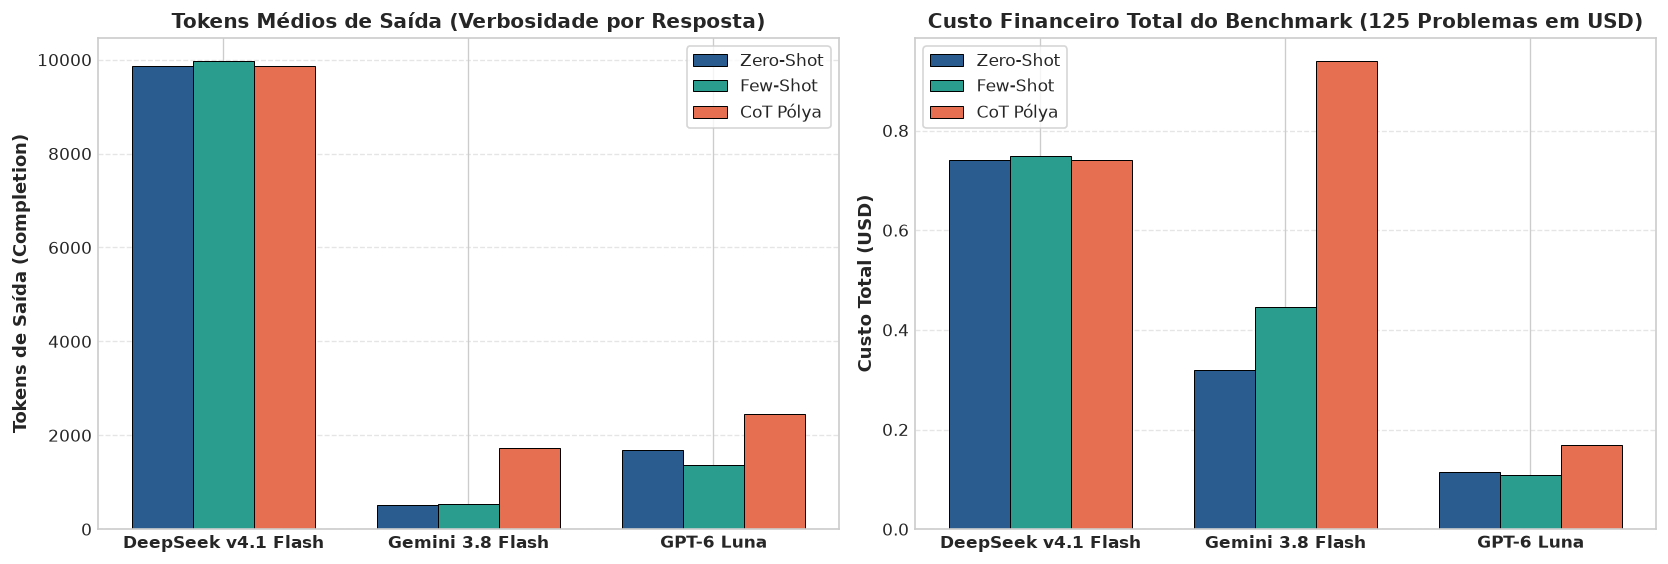

In [12]:
# Extração consolidada de tokens e custos econômicos em C (T=0)
token_comparison = []

prompt_map = {
    "Zero-Shot": datas_zero_shot,
    "Few-Shot": datas_few_shot,
    "CoT Pólya": datas_cot_polya
}

for strat_display, strat_dict in prompt_map.items():
    for m in main_models:
        df_sub = strat_dict[m]
        in_tok_mean = df_sub["input_tokens"].mean()
        out_tok_mean = df_sub["output_tokens"].mean()
        tot_cost = df_sub["cost_usd"].sum()
        ac_count = (df_sub["judge_predict"] == "AC").sum()
        
        token_comparison.append({
            "Modelo": m,
            "Estratégia": strat_display,
            "Input Tokens (Médio)": f"{in_tok_mean:.1f}",
            "Output Tokens (Médio)": f"{out_tok_mean:.1f}",
            "Custo Total (USD)": f"${tot_cost:.4f}",
            "Custo / AC (USD)": f"${tot_cost / ac_count:.5f}" if ac_count > 0 else "-"
        })

df_tokens = pd.DataFrame(token_comparison)
print("=== QUADRO DE CUSTO COMPUTACIONAL E ECONÔMICO (RQ4, T=0) ===")
display(df_tokens)

# Gráfico 5: Análise de Verbosidade de Saída e Eficiência de Custo
fig, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(14, 4.8))

x_k = np.arange(len(main_models))
w_k = 0.25

out_zero = [datas_zero_shot[m]["output_tokens"].mean() for m in main_models]
out_few = [datas_few_shot[m]["output_tokens"].mean() for m in main_models]
out_cot = [datas_cot_polya[m]["output_tokens"].mean() for m in main_models]

cost_zero = [datas_zero_shot[m]["cost_usd"].sum() for m in main_models]
cost_few = [datas_few_shot[m]["cost_usd"].sum() for m in main_models]
cost_cot = [datas_cot_polya[m]["cost_usd"].sum() for m in main_models]

ax5a.bar(x_k - w_k, out_zero, width=w_k, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
ax5a.bar(x_k, out_few, width=w_k, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
ax5a.bar(x_k + w_k, out_cot, width=w_k, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)
ax5a.set_title("Tokens Médios de Saída (Verbosidade por Resposta)")
ax5a.set_xticks(x_k)
ax5a.set_xticklabels(main_models, fontweight='bold')
ax5a.set_ylabel("Tokens de Saída (Completion)")
ax5a.legend(loc='upper right', frameon=True)
ax5a.grid(axis='y', linestyle='--', alpha=0.5)

ax5b.bar(x_k - w_k, cost_zero, width=w_k, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
ax5b.bar(x_k, cost_few, width=w_k, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
ax5b.bar(x_k + w_k, cost_cot, width=w_k, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)
ax5b.set_title("Custo Financeiro Total do Benchmark (125 Problemas em USD)")
ax5b.set_xticks(x_k)
ax5b.set_xticklabels(main_models, fontweight='bold')
ax5b.set_ylabel("Custo Total (USD)")
ax5b.legend(loc='upper left', frameon=True)
ax5b.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
